# Simulate a cohort

In this tutorial we grow a small cohort of patients over one configuration with [`Cohort`](https://pedrofale.github.io/iscc/reference/Cohort/), generate scRNA for each patient, pool the patients into sequencing batches and read the answer key across patients.
The patients share the layout seed, which draws the driver genes and the baseline expression of each cell type.
Each patient has its own evolution seed, which draws the gland field, the clones, the mutations and the spatial history of the patient.
The tool tutorials on [batch integration](tool_integration.ipynb) and [progression models](tool_mhn.ipynb) build on such a cohort.
The notebook runs in about a minute on a laptop.

In [1]:
import os
import warnings
os.environ["KMP_WARNINGS"] = "0"  # silence a deprecation notice of OpenMP in the UMAP dependencies
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="numba")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="max_cells")  # each sample is a subsample by design

import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

from iscc.cohort import Cohort, clone_key, concat_cohort_batches, recurrence_table, run_cohort_batches, shared_private_labels
from iscc.integrations import biological_types, clones_from_clades
from iscc.sample import Resection
from iscc.tumor import GenotypeTumor

## Grow the cohort

`Cohort` calls a growth function once per patient, with the evolution seed of the patient and the shared layout seed.
Our growth function builds the tumor of `tutorial_config.yaml`, as in the [Quickstart](01_quickstart.ipynb), and grows it to 6,000 cancer cells, a small tumor in situ that has spread from its founding gland to the other glands.

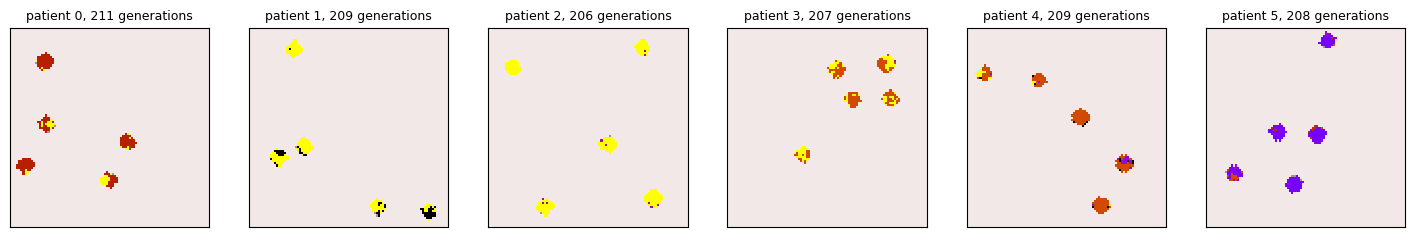

In [2]:
def grow(seed, layout_seed):
    tumor = GenotypeTumor(config="tutorial_config.yaml", seed=seed, layout_seed=layout_seed)
    tumor.grow(n_steps=1000, target_cancer=6000, materialize=False)
    return tumor


cohort = Cohort(grow, patient_seeds=[11, 12, 13, 14, 15, 16]).run()

fig, axes = plt.subplots(1, cohort.n_patients, figsize=(3 * cohort.n_patients, 3))
for ax, patient in zip(axes, cohort.patients):
    patient.tumor.plot_tissue(ax=ax, color="clone", min_freq=0.05)
    ax.set_title(f"patient {patient.patient_id}, {patient.tumor.time:.0f} generations", fontsize=9)
plt.show()

Every patient reached 6,000 cancer cells after 206 to 211 generations, with cancer cells in all five glands, and one or two driver clones dominate each patient.

## Sample each patient

We resect a window of 20 by 20 demes, about 1 mm across, centered on the founding gland of each patient, and dissociate it into a sample of 3,000 cells with a [`Resection`](https://pedrofale.github.io/iscc/reference/Resection/).
With `install=True` the sample becomes the cell table of the patient, which the cohort functions below read.
We then label the cancer cells of each patient with clones, which are clades of the true genealogy with at least 30 sampled cells ([`clones_from_clades`](https://pedrofale.github.io/iscc/reference/clones_from_clades/)).

In [3]:
clone = {}
for patient in cohort.patients:
    tumor = patient.tumor
    region = tumor.primary_window(side=20, center=tumor.gland_centers[0])
    sample = Resection(tumor).dissociate(region=region, max_cells=3000, install=True, layers="scrna", seed=patient.seed)
    labels = clones_from_clades(tumor, min_cells=30)
    clone.update({clone_key(patient.patient_id, cell): f"P{patient.patient_id} {label}"
                  for cell, label in labels.dropna().items()})
    types = pd.Series(biological_types(sample["cell_type"]["cell_id"])).value_counts()
    print(f"patient {patient.patient_id}: {types.to_dict()}, {labels.cat.categories.size} clone labels")

patient 0: {'stromal': 1487, 'cancer': 973, 'epithelial': 579}, 3 clone labels


patient 1: {'stromal': 1251, 'cancer': 1062, 'epithelial': 724}, 7 clone labels


patient 2: {'stromal': 1404, 'cancer': 1019, 'epithelial': 549}, 6 clone labels


patient 3: {'stromal': 1497, 'cancer': 933, 'epithelial': 599}, 4 clone labels


patient 4: {'stromal': 1455, 'cancer': 919, 'epithelial': 563}, 6 clone labels


patient 5: {'stromal': 1495, 'cancer': 999, 'epithelial': 550}, 7 clone labels


Each sample contains about 1,000 cancer cells, 1,250 to 1,500 stromal cells and 550 to 720 epithelial cells, and the clone labels of a patient include `other` for the cancer cells outside every clade.

## Pool the patients into sequencing batches

`run_cohort_batches` draws scRNA for 500 cells of each patient and assigns the patients to sequencing batches, where each batch is one realization of the technical noise of [`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/).
With `mapping="one_to_one"` each patient is sequenced in its own batch, so that batch and patient are confounded.
With `mapping="multiplex"` and `capacity=3`, three patients share each batch, as in a design with cell hashing or genetic demultiplexing, so that each batch contains cells of several patients.
`concat_cohort_batches` joins the batches into one AnnData with the patient and the batch of each cell.

In [4]:
designs = {}
for mapping, capacity in (("one_to_one", None), ("multiplex", 3)):
    assays, batches, assignment = run_cohort_batches(cohort, mapping=mapping, capacity=capacity, n_cells_per_patient=500)
    adata = concat_cohort_batches(assays)
    cell = adata.obs_names.str.rsplit("-", n=1).str[0]
    adata.obs["patient"] = adata.obs["patient"].astype(str)
    adata.obs["cell_type"] = biological_types(adata.obs["clone"])
    adata.obs["clone"] = cell.map(clone).values
    designs[mapping] = adata
    print(f"{mapping}: {adata.n_obs:,} cells, batches {batches}")

one_to_one: 3,000 cells, batches {0: [0], 1: [1], 2: [2], 3: [3], 4: [4], 5: [5]}


multiplex: 3,000 cells, batches {0: [0, 1, 2], 1: [3, 4, 5]}


We run the standard scanpy workflow on each design and color the cells by patient, batch and cell type, without any batch correction.

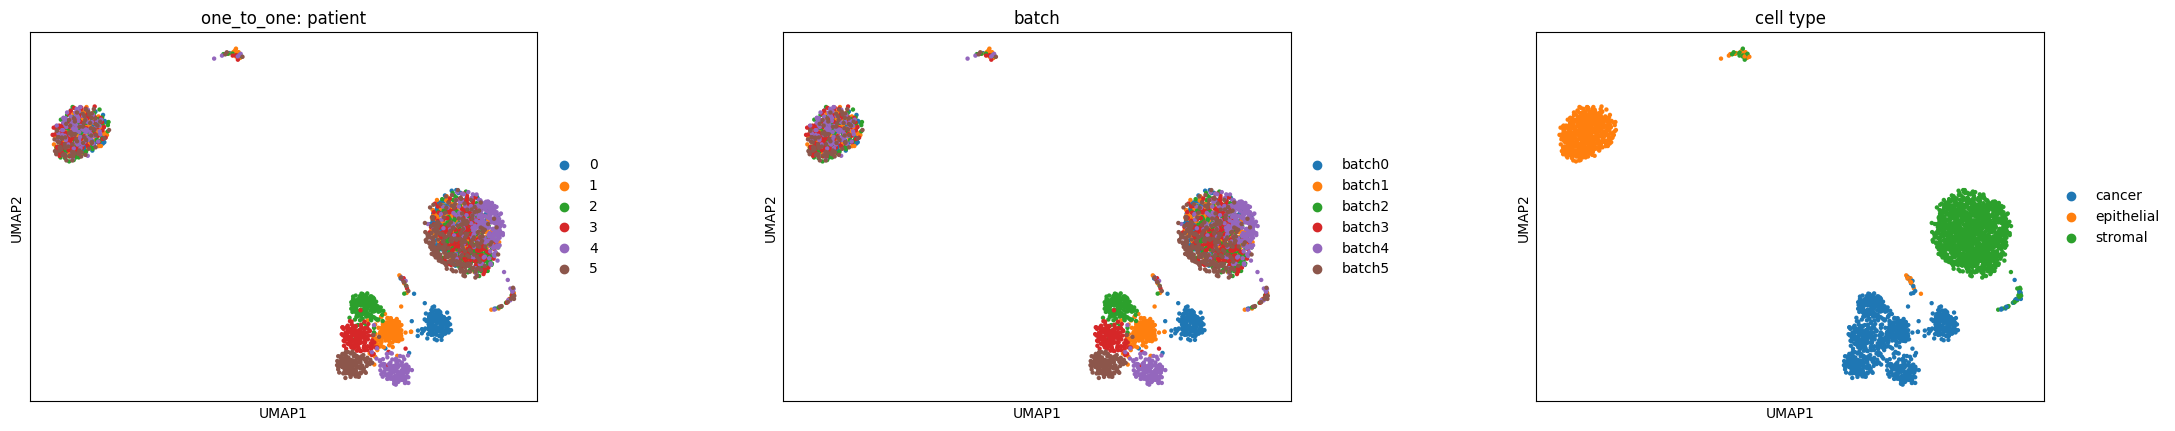

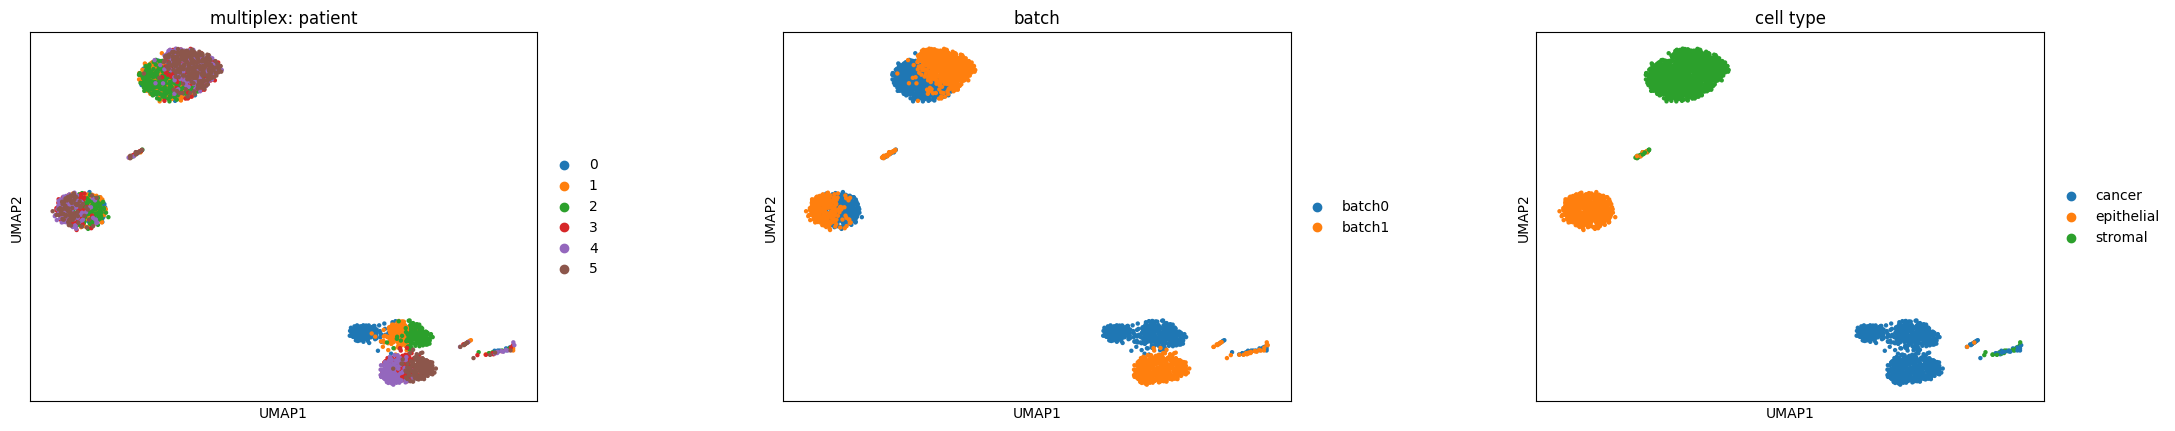

In [5]:
for mapping, adata in designs.items():
    adata.layers["counts"] = adata.X.copy()
    sc.pp.normalize_total(adata)
    sc.pp.log1p(adata)
    sc.pp.pca(adata)
    sc.pp.neighbors(adata)
    sc.tl.umap(adata)
    sc.pl.umap(adata, color=["patient", "batch", "cell_type"], wspace=0.35, title=[f"{mapping}: patient", "batch", "cell type"])

With one batch per patient, the stromal and epithelial cells of all patients overlap, apart from part of the stromal cells of patient 4, and the cancer cells form one cluster per patient, in which patient and batch cannot be told apart.
With three patients per batch, the stromal, epithelial and cancer cells split by batch, which is the batch effect an integration method should remove, while the cancer cells within a batch still separate by patient.

## Read the answer key across patients

`shared_private_labels` gives each cell two labels.
The shared state is the cell type, which an integration method should align across patients, and the private state is the patient, which the method should keep apart.
The clone labels are private by construction, since each patient has its own genealogy.

In [6]:
adata = designs["multiplex"]
states = shared_private_labels(adata.obs)
print(pd.crosstab(states["shared_state"], states["private_state"]).to_string())
print(f"\n{adata.obs['clone'].nunique()} clone labels over {adata.obs['patient'].nunique()} patients")

private_state    0    1    2    3    4    5
shared_state                               
cancer         166  178  173  162  150  172
epithelial     105  124  106   98  108   82
stromal        229  198  221  240  242  246

33 clone labels over 6 patients


`recurrence_table` gives for every gene the number of patients in which it is mutated in at least 5% of the cancer cells, together with the true role of the gene, which is the answer key for the detection of recurrent drivers.

In [7]:
recurrence = recurrence_table(cohort)
print(pd.crosstab(recurrence["n_patients_mutated"], recurrence["is_driver"].map({True: "driver", False: "other gene"})).to_string())
recurrence[recurrence["is_driver"]].sort_values("n_patients_mutated", ascending=False).head(8)

is_driver           driver  other gene
n_patients_mutated                    
0                      210        5097
1                       25         635
2                        1          30
3                        0           2


,is_oncogene,is_tsg,n_patients_mutated,recurrence,is_driver,is_recurrent
gene,,,,,,
G_3_67,False,True,2,0.333333,True,True
G_1_325,False,True,1,0.166667,True,False
G_2_383,True,False,1,0.166667,True,False
G_9_272,False,True,1,0.166667,True,False
G_5_269,True,False,1,0.166667,True,False
G_4_114,False,True,1,0.166667,True,False
G_7_212,True,False,1,0.166667,True,False
G_5_150,True,False,1,0.166667,True,False


In this small cohort the driver genes are mutated about as often as the other genes, since 26 of the 236 drivers and 667 of the 5,764 other genes are mutated in at least one patient, and only one tumor suppressor gene is mutated in two patients.
Recurrence therefore does not single out the drivers here, possibly because selection at a driver effect of 1.03 is weak, and a benchmark of driver detection may need more patients or a larger driver effect ([Shape the tumor](02_shape_the_tumor.ipynb)).

## Next steps

[Batch integration](tool_integration.ipynb) integrates the pooled scRNA of a cohort with Harmony and scVI, and [Progression models](tool_mhn.ipynb) learns the order of events from the DNA of a cohort with a mutual hazard network (MHN).